# Classificação de Intenções (`question_type`) — TP4 HealthAssist

Classificação multiclasse de **intenção** de perguntas médicas em português: prever `question_type` (7 classes) a partir do texto `question`.

Este notebook reutiliza as funções de `classificacao_tp4.py` (mesma lógica do script reprodutível) e mostra as saídas: distribuição das classes, melhores hiperparâmetros do `GridSearchCV`, `classification_report`, comparação com baseline e a matriz de confusão.

In [1]:
import hashlib, json
from pathlib import Path

import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
    classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import (GridSearchCV, GroupShuffleSplit,
    StratifiedGroupKFold)
import joblib

from classificacao_tp4 import (DATASET, MODELS, MODEL_PATH, MANIFEST_PATH,
    CONFUSION_PNG, RANDOM_STATE, MODEL_VERSION, SKLEARN_VERSION,
    construir_pipeline, preprocessar_texto)
MODELS.mkdir(parents=True, exist_ok=True)
print('sklearn version esperada:', SKLEARN_VERSION)

sklearn version esperada: 1.9.1


## 1. Dados e distribuição das classes

In [2]:
df = pd.read_csv(DATASET).dropna(subset=['question', 'question_type']).copy()
X = df['question'].astype(str).tolist()
y = df['question_type'].astype(str).tolist()
groups = df['question'].astype(str).tolist()
print('linhas:', len(df), '| perguntas unicas:', df['question'].nunique())
df['question_type'].value_counts()

linhas: 5000 | perguntas unicas: 1646


question_type
Tratamento                           2187
Diagnóstico                          1653
Escolha de profissionais de saúde     376
Epidemiologia                         321
Estilo de vida saudável               239
Outros                                156
Anatomia e fisiologia                  68
Name: count, dtype: int64

## 2. Split sem vazamento (GroupShuffleSplit, groups=question)

In [3]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train = [X[i] for i in train_idx]; y_train = [y[i] for i in train_idx]
g_train = [groups[i] for i in train_idx]
X_test = [X[i] for i in test_idx]; y_test = [y[i] for i in test_idx]
assert not (set(X_train) & set(X_test)), 'vazamento!'
print('treino:', len(X_train), '| teste:', len(X_test), '| sem vazamento OK')

treino: 3793 | teste: 1207 | sem vazamento OK


## 3. GridSearchCV (scoring=f1_macro) — 3 hiperparâmetros, 3 valores cada

In [4]:
param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'tfidf__min_df': [1, 2, 3],
    'clf__C': [0.1, 1.0, 10.0],
}
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(construir_pipeline(), param_grid, scoring='f1_macro',
    cv=cv, n_jobs=-1, verbose=0, refit=True)
grid.fit(X_train, y_train, groups=g_train)
best_params = grid.best_params_
print('melhores params:', best_params)
print('melhor f1_macro (CV): %.4f' % grid.best_score_)

melhores params: {'clf__C': 1.0, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 1)}
melhor f1_macro (CV): 0.4303


## 4. Avaliação no teste — classification_report, F1-macro, acurácia

In [5]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
labels_sorted = sorted(set(y))
f1_macro = f1_score(y_test, y_pred, average='macro')
accuracy = accuracy_score(y_test, y_pred)
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
print('F1-macro = %.4f | acuracia = %.4f' % (f1_macro, accuracy))

                                   precision    recall  f1-score   support

            Anatomia e fisiologia      0.148     0.182     0.163        22
                      Diagnóstico      0.741     0.801     0.770       407
                    Epidemiologia      0.443     0.595     0.508        79
Escolha de profissionais de saúde      0.720     0.628     0.671        86
          Estilo de vida saudável      0.702     0.371     0.485        89
                           Outros      0.200     0.250     0.222        16
                       Tratamento      0.823     0.797     0.810       508

                         accuracy                          0.723      1207
                        macro avg      0.540     0.518     0.518      1207
                     weighted avg      0.734     0.723     0.723      1207

F1-macro = 0.5185 | acuracia = 0.7233


## 5. Baseline (DummyClassifier most_frequent)

In [6]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
y_dummy = dummy.predict(X_test)
baseline_f1 = f1_score(y_test, y_dummy, average='macro')
baseline_acc = accuracy_score(y_test, y_dummy)
print('Baseline  F1-macro = %.4f | acuracia = %.4f' % (baseline_f1, baseline_acc))
print('Modelo    F1-macro = %.4f | acuracia = %.4f' % (f1_macro, accuracy))
print('Ganho F1-macro: +%.4f' % (f1_macro - baseline_f1))

Baseline  F1-macro = 0.0846 | acuracia = 0.4209
Modelo    F1-macro = 0.5185 | acuracia = 0.7233
Ganho F1-macro: +0.4339


## 6. Matriz de confusão (teste)

A figura também é salva em `eda/matriz_confusao.png`.

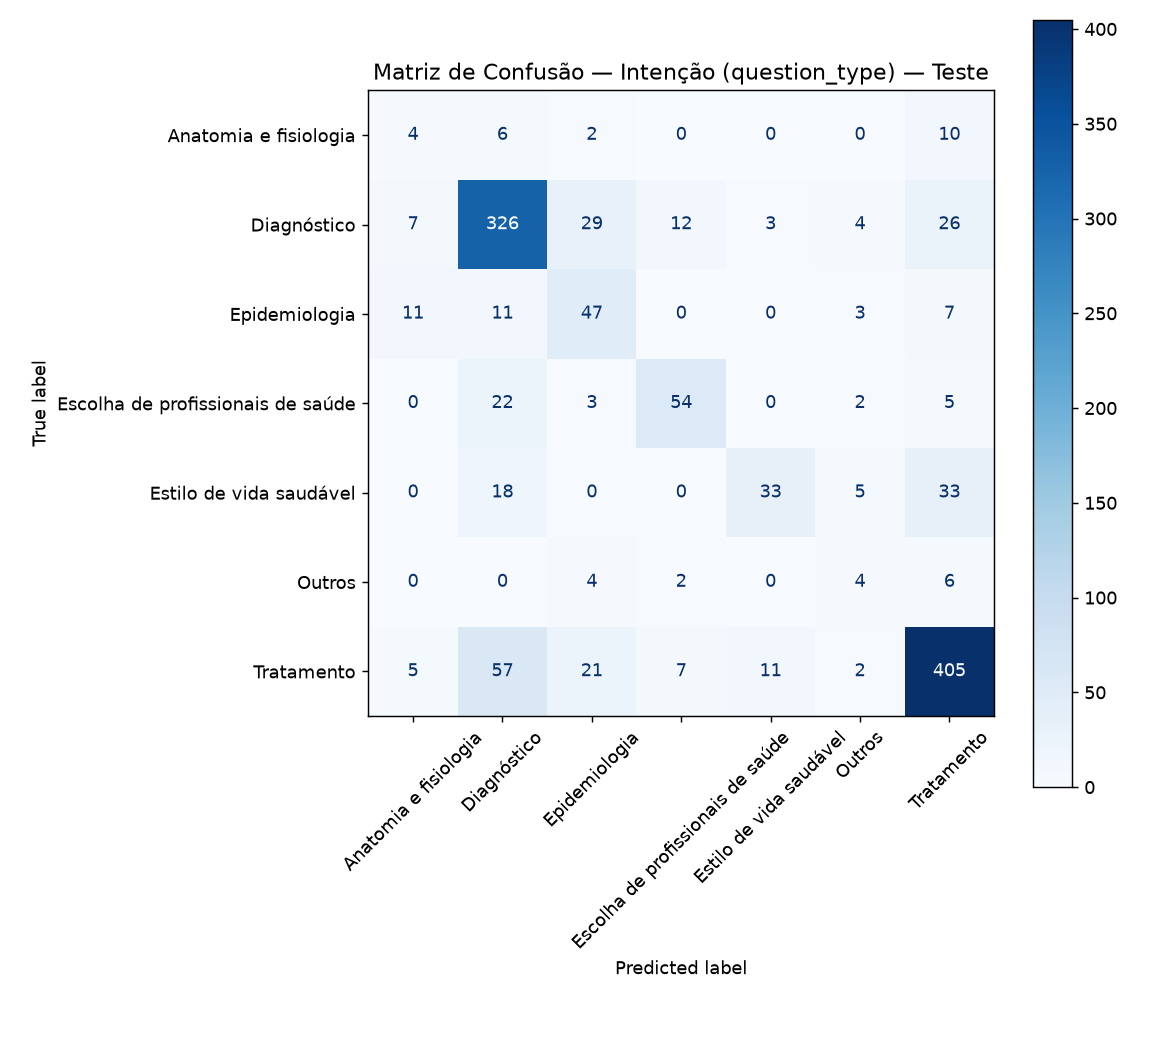

In [7]:
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=labels_sorted).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, colorbar=True)
ax.set_title('Matriz de Confusão — Intenção (question_type) — Teste')
plt.tight_layout()
fig.savefig(CONFUSION_PNG, dpi=130)
from IPython.display import Image, display
display(Image(filename=str(CONFUSION_PNG)))

## 7. Re-treino no dataset inteiro + serialização + manifest

O modelo serializado é um `Pipeline` que recebe `list[str]` cru e expõe `predict_proba` e `classes_` (contrato do endpoint `/classify`).

In [8]:
final_model = construir_pipeline()
final_model.set_params(**best_params)
final_model.fit(X, y)
joblib.dump(final_model, MODEL_PATH)
classes = list(final_model.classes_)
sha256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
manifest = {
    'version': MODEL_VERSION, 'sha256': sha256,
    'sklearn_version': SKLEARN_VERSION, 'classes': classes,
    'best_params': {'tfidf__ngram_range': list(best_params['tfidf__ngram_range']),
        'tfidf__min_df': best_params['tfidf__min_df'], 'clf__C': best_params['clf__C']},
    'metrics': {'f1_macro': round(float(f1_macro), 4), 'accuracy': round(float(accuracy), 4),
        'baseline_f1_macro': round(float(baseline_f1), 4), 'baseline_accuracy': round(float(baseline_acc), 4)},
    'n_train': int(len(X_train)), 'n_test': int(len(X_test)), 'language': 'pt'}
MANIFEST_PATH.write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
assert hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest() == manifest['sha256']
print('classes_:', classes)
print('sha256:', sha256)
manifest

classes_: [np.str_('Anatomia e fisiologia'), np.str_('Diagnóstico'), np.str_('Epidemiologia'), np.str_('Escolha de profissionais de saúde'), np.str_('Estilo de vida saudável'), np.str_('Outros'), np.str_('Tratamento')]
sha256: 2a53a92513ca6bfc0b21a23a5037f0b589dbfc65eecb0d9dd01969e88af67ec7


{'version': 'healthassist-intents-tp4-v1',
 'sha256': '2a53a92513ca6bfc0b21a23a5037f0b589dbfc65eecb0d9dd01969e88af67ec7',
 'sklearn_version': '1.9.1',
 'classes': [np.str_('Anatomia e fisiologia'),
  np.str_('Diagnóstico'),
  np.str_('Epidemiologia'),
  np.str_('Escolha de profissionais de saúde'),
  np.str_('Estilo de vida saudável'),
  np.str_('Outros'),
  np.str_('Tratamento')],
 'best_params': {'tfidf__ngram_range': [1, 1],
  'tfidf__min_df': 3,
  'clf__C': 1.0},
 'metrics': {'f1_macro': 0.5185,
  'accuracy': 0.7233,
  'baseline_f1_macro': 0.0846,
  'baseline_accuracy': 0.4209},
 'n_train': 3793,
 'n_test': 1207,
 'language': 'pt'}

## 8. Verificação do contrato

`joblib.load(...).predict(['...'])` funciona sobre texto cru.

In [9]:
carregado = joblib.load(MODEL_PATH)
exemplo = ['Qual o melhor tratamento para dor no joelho?',
           'Essa doenca e contagiosa? Quantas pessoas pegam por ano?']
print('predict:', carregado.predict(exemplo).tolist())
print('predict_proba shape:', carregado.predict_proba(exemplo).shape)
print('classes_:', list(carregado.classes_))

predict: ['Tratamento', 'Epidemiologia']
predict_proba shape: (2, 7)
classes_: [np.str_('Anatomia e fisiologia'), np.str_('Diagnóstico'), np.str_('Epidemiologia'), np.str_('Escolha de profissionais de saúde'), np.str_('Estilo de vida saudável'), np.str_('Outros'), np.str_('Tratamento')]
